# Tuần 9 — Threshold sweep B0/B1 YOLOv8s trên Validation

Notebook này thực hiện inference một lần trên validation, dựng sweep cho cặp ngưỡng `tau_critical` / `tau_regular`, chọn ngưỡng theo tiêu chí đã có trong project và tạo cấu hình riêng cho dòng YOLOv8s. Không train, không đọc `test.txt`, không đụng `configs/threshold.yaml` (cấu hình đó thuộc YOLO11s).

**Quy tắc khóa:** Open_circuit/Short dùng `tau_critical`; bốn lớp còn lại dùng `tau_regular`. Chọn cặp có F2 micro cao nhất thỏa đồng thời Recall critical `>=0.95`, Recall riêng từng lớp critical `>=0.94`, Board-FR `=0`. F2 = `5PR/(4P+R)`. Tie-break: Precision cao hơn, sau đó tau_regular cao hơn, rồi tau_critical cao hơn.

Ngưỡng quét `0.01–0.95`, bước `0.01`; NMS IoU `0.7`; matching class-aware, one-to-one, IoU `>=0.50`. Validation hiện không có ảnh sạch nên Board-FA được ghi N/A, không dùng làm ràng buộc.

## 1. Thư viện, protocol và xác thực đầu vào
Mở notebook từ project root hoặc thư mục `scripts`. Trên máy Mac, inference được ép về CPU để tránh lỗi bộ nhớ MPS đã gặp ở YOLOv8s-P2; trên Kaggle/CUDA sẽ dùng GPU.

In [1]:
import hashlib, json, time
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from ultralytics import YOLO
from PIL import Image

CLASSES=['Missing_hole','Mouse_bite','Open_circuit','Short','Spur','Spurious_copper']
CRITICAL_IDS={2,3}
TAUS=np.round(np.arange(0.01,0.951,0.01),2)
IMGSZ=1024; PREDICT_MIN_CONF=0.001; NMS_IOU=0.7; MATCH_IOU=0.50
BETA=2.0; CRITICAL_RECALL_MIN=0.95; PER_CRITICAL_RECALL_MIN=0.94; BOARD_FR_MAX=0.0
cwd=Path.cwd().resolve()
ROOT=next((p for p in (cwd,*cwd.parents) if (p/'configs'/'yolov8s-p2.yaml').is_file()),None)
assert ROOT is not None,'Mở notebook trong project PCB-DetectionImprove.'
VAL_TXT=ROOT/'data/splits/val.txt'; DATA_YAML=ROOT/'data/data.yaml'
CHECKPOINTS={
 'B0 (YOLOv8s)':ROOT/'runs/B0_yolov8s_100ep_batch16/weights/best.pt',
 'B1 (YOLOv8s-P2)':ROOT/'runs/B1_yolov8s_p2_100ep/weights/best.pt'}
assert VAL_TXT.is_file() and DATA_YAML.is_file()
for name,path in CHECKPOINTS.items(): assert path.is_file(),f'{name}: thiếu checkpoint {path}'
if torch.cuda.is_available(): DEVICE=0; BATCH=8; DEVICE_NAME=torch.cuda.get_device_name(0)
else: DEVICE='cpu'; BATCH=4; DEVICE_NAME='CPU (MPS avoided for P2 inference)'
def resolve_image(line):
 p=Path(line); return (p if p.is_absolute() else ROOT/p).resolve()
def label_path(image):
 parts=list(image.parts); assert 'images' in parts,f'Không nhận diện được label cho {image}'
 parts[parts.index('images')]='labels'; return Path(*parts).with_suffix('.txt')
VAL_LINES=[s.strip() for s in VAL_TXT.read_text(encoding='utf-8').splitlines() if s.strip()]
assert len(VAL_LINES)==608,f'Val split mong đợi 608 ảnh, có {len(VAL_LINES)}'
VAL_IMAGES=[resolve_image(s) for s in VAL_LINES]
missing=[p for p in VAL_IMAGES if not p.is_file() or not label_path(p).is_file()]
assert not missing,f'Thiếu ảnh/label val: {missing[:3]}'
print('Project:',ROOT,'| Validation:',len(VAL_IMAGES),'| device:',DEVICE_NAME,'| batch:',BATCH)
print('Split SHA256:',hashlib.sha256(VAL_TXT.read_bytes()).hexdigest())
print('Validation chỉ có ảnh có lỗi; clean images:',sum(not label_path(p).read_text(encoding='utf-8').strip() for p in VAL_IMAGES))

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Project: /Users/duytan/orca/projects/PCB-DetectionImprove | Validation: 608 | device: CPU (MPS avoided for P2 inference) | batch: 4
Split SHA256: 1763fb6be3f9a52bdec47fd95ee008a99c61957c2d65309ed9e52268f6d87eaa
Validation chỉ có ảnh có lỗi; clean images: 0


## 2. Inference và matching một lần cho mỗi model
Mỗi prediction được giữ từ confidence `0.001` trở lên để sweep ngưỡng offline. Với từng ảnh, detections được sắp theo confidence giảm dần rồi ghép greedy với GT cùng lớp; TP/FP tích lũy theo confidence cho phép tính mọi ngưỡng mà không chạy model lại.

In [2]:
def iou_xyxy(one, boxes):
 if len(boxes)==0:return np.empty(0,dtype=float)
 x1=np.maximum(one[0],boxes[:,0]); y1=np.maximum(one[1],boxes[:,1])
 x2=np.minimum(one[2],boxes[:,2]); y2=np.minimum(one[3],boxes[:,3])
 inter=np.maximum(0,x2-x1)*np.maximum(0,y2-y1)
 a=max(0,one[2]-one[0])*max(0,one[3]-one[1])
 b=np.maximum(0,boxes[:,2]-boxes[:,0])*np.maximum(0,boxes[:,3]-boxes[:,1])
 return inter/np.maximum(a+b-inter,1e-9)

def load_ground_truth(image):
 with Image.open(image) as im:iw,ih=im.size
 rows=[]
 for line in label_path(image).read_text(encoding='utf-8').splitlines():
  v=line.split()
  if len(v)<5:continue
  cid,xc,yc,w,h=map(float,v[:5]); cid=int(cid)
  if cid not in range(6):continue
  rows.append((cid,np.array([(xc-w/2)*iw,(yc-h/2)*ih,(xc+w/2)*iw,(yc+h/2)*ih],dtype=float)))
 return rows

def collect_model_records(model_name,checkpoint):
 model=YOLO(str(checkpoint)); gt_by_image=[]; det_rows=[]; max_scores=np.zeros((len(VAL_IMAGES),6),dtype=float)
 t0=time.time()
 for start in range(0,len(VAL_IMAGES),32):
  chunk=VAL_IMAGES[start:start+32]
  predictions=model.predict(source=[str(p) for p in chunk],imgsz=IMGSZ,batch=BATCH,device=DEVICE,
   conf=PREDICT_MIN_CONF,iou=NMS_IOU,max_det=300,stream=False,verbose=False)
  for offset,(image,pred) in enumerate(zip(chunk,predictions)):
   image_idx=start+offset; gt=load_ground_truth(image); gt_by_image.append(gt)
   if pred.boxes is None or len(pred.boxes)==0:continue
   pb=pred.boxes.xyxy.cpu().numpy(); pc=pred.boxes.cls.cpu().numpy().astype(int); ps=pred.boxes.conf.cpu().numpy()
   order=np.argsort(-ps); matched=set()
   for pi in order:
    cid=int(pc[pi]); max_scores[image_idx,cid]=max(max_scores[image_idx,cid],float(ps[pi]))
    candidates=[j for j,(gc,_) in enumerate(gt) if gc==cid and j not in matched]
    is_tp=False
    if candidates:
     boxes=np.stack([gt[j][1] for j in candidates]); overlaps=iou_xyxy(pb[pi],boxes); k=int(np.argmax(overlaps))
     if overlaps[k]>=MATCH_IOU:matched.add(candidates[k]);is_tp=True
    det_rows.append((cid,float(ps[pi]),int(is_tp)))
  del predictions
  if (start+len(chunk))%128==0 or start+len(chunk)==len(VAL_IMAGES):
   print(f'{model_name}: processed {start+len(chunk)}/{len(VAL_IMAGES)} val images')
 del model
 import gc; gc.collect()
 print(f'{model_name}: collected {len(det_rows):,} detections in {(time.time()-t0)/60:.1f} min')
 return gt_by_image,det_rows,max_scores

model_records={}
for model_name,checkpoint in CHECKPOINTS.items():
 model_records[model_name]=collect_model_records(model_name,checkpoint)
for model_name,checkpoint in CHECKPOINTS.items():
 model_records[model_name]=collect_model_records(model_name,checkpoint)

B0 (YOLOv8s): processed 128/608 val images


B0 (YOLOv8s): processed 256/608 val images


B0 (YOLOv8s): processed 384/608 val images


B0 (YOLOv8s): processed 512/608 val images


B0 (YOLOv8s): processed 608/608 val images
B0 (YOLOv8s): collected 60,827 detections in 6.2 min


B1 (YOLOv8s-P2): processed 128/608 val images


... (10 outputs left out)

B1 (YOLOv8s-P2): processed 256/608 val images


B1 (YOLOv8s-P2): processed 384/608 val images


B1 (YOLOv8s-P2): processed 512/608 val images


B1 (YOLOv8s-P2): processed 608/608 val images
B1 (YOLOv8s-P2): collected 24,908 detections in 9.3 min


## 3. Tính sweep 95 × 95 và chọn cặp khả thi
`Board-FR` ở đây giữ đúng định nghĩa trong cấu hình hiện có của project: ảnh có lỗi nhưng dự đoán PASS. `Board-FA` là ảnh sạch nhưng dự đoán DEFECTIVE; vì validation không có ảnh sạch nên N/A.

In [3]:
def sweep_model(model_name,records):
 gt_by_image,det_rows,max_scores=records
 gt_counts=np.zeros(6,dtype=int)
 for gt in gt_by_image:
  for cid,_ in gt:gt_counts[cid]+=1
 assert gt_counts.sum()>0
 tp_curve=np.zeros((6,len(TAUS)),dtype=int); fp_curve=np.zeros_like(tp_curve)
 for cid in range(6):
  rows=[r for r in det_rows if r[0]==cid]
  if not rows:continue
  scores=np.asarray([r[1] for r in rows]); is_tp=np.asarray([r[2] for r in rows],dtype=int)
  keep=scores[:,None]>=TAUS[None,:]
  tp_curve[cid]=(keep*is_tp[:,None]).sum(axis=0)
  fp_curve[cid]=(keep*(1-is_tp)[:,None]).sum(axis=0)
 rows=[]
 critical_det=max_scores[:,list(CRITICAL_IDS)].max(axis=1)
 regular_ids=[c for c in range(6) if c not in CRITICAL_IDS]
 regular_det=max_scores[:,regular_ids].max(axis=1)
 defective=np.asarray([len(gt)>0 for gt in gt_by_image])
 clean=~defective; n_def=int(defective.sum()); n_clean=int(clean.sum())
 for ic,tauc in enumerate(TAUS):
  for ir,taur in enumerate(TAUS):
   idx=np.asarray([ic if c in CRITICAL_IDS else ir for c in range(6)])
   tp=tp_curve[np.arange(6),idx]; fp=fp_curve[np.arange(6),idx]; fn=gt_counts-tp
   total_tp=int(tp.sum()); total_fp=int(fp.sum()); total_gt=int(gt_counts.sum())
   precision=total_tp/(total_tp+total_fp) if total_tp+total_fp else 0.0
   recall=total_tp/total_gt if total_gt else 0.0
   f2=(5*precision*recall)/(4*precision+recall) if 4*precision+recall else 0.0
   critical_recall=int(tp[2]+tp[3])/int(gt_counts[2]+gt_counts[3])
   r_open=tp[2]/gt_counts[2] if gt_counts[2] else np.nan
   r_short=tp[3]/gt_counts[3] if gt_counts[3] else np.nan
   pred_defective=(critical_det>=tauc)|(regular_det>=taur)
   board_fr=int((defective&~pred_defective).sum())/n_def if n_def else np.nan
   board_fa=int((clean&pred_defective).sum())/n_clean if n_clean else np.nan
   feasible=(critical_recall>=CRITICAL_RECALL_MIN and r_open>=PER_CRITICAL_RECALL_MIN and
             r_short>=PER_CRITICAL_RECALL_MIN and board_fr<=BOARD_FR_MAX)
   rows.append({'model':model_name,'tau_critical':float(tauc),'tau_regular':float(taur),
    'TP':total_tp,'FP':total_fp,'FN':total_gt-total_tp,'precision':precision,'recall':recall,'F2':f2,
    'critical_recall':critical_recall,'recall_open_circuit':r_open,'recall_short':r_short,
    'board_fr_defect_predicted_pass':board_fr,'board_fa_clean_predicted_defective':board_fa,
    'clean_images':n_clean,'defective_images':n_def,'feasible':bool(feasible)})
 df=pd.DataFrame(rows)
 candidates=df[df.feasible].sort_values(['F2','precision','tau_regular','tau_critical'],ascending=[False,False,False,False])
 selected=None if candidates.empty else candidates.iloc[0].to_dict()
 return df,selected,gt_counts

sweep_tables={}; selected_rows=[]; gt_counts_by_model={}
for model_name,records in model_records.items():
 df,selected,gtc=sweep_model(model_name,records);sweep_tables[model_name]=df;gt_counts_by_model[model_name]=gtc
 print(f'{model_name}: feasible pairs = {int(df.feasible.sum()):,}/{len(df):,}')
 if selected is None:print('NO FEASIBLE THRESHOLD under the pre-registered constraints.')
 else:selected_rows.append(selected);display(pd.DataFrame([selected]))
sweep_df=pd.concat(sweep_tables.values(),ignore_index=True)
display(sweep_df.groupby('model').agg(feasible_pairs=('feasible','sum'),best_F2=('F2','max'),best_critical_recall=('critical_recall','max')))

B0 (YOLOv8s): feasible pairs = 124/9,025


,model,tau_critical,tau_regular,TP,FP,FN,precision,recall,F2,critical_recall,recall_open_circuit,recall_short,board_fr_defect_predicted_pass,board_fa_clean_predicted_defective,clean_images,defective_images,feasible
0,B0 (YOLOv8s),0.02,0.58,2664,4668,396,0.363339,0.870588,0.680564,0.955882,0.942748,0.969758,0.0,NaN,0,608,True


B1 (YOLOv8s-P2): feasible pairs = 72/9,025


,model,tau_critical,tau_regular,TP,FP,FN,precision,recall,F2,critical_recall,recall_open_circuit,recall_short,board_fr_defect_predicted_pass,board_fa_clean_predicted_defective,clean_images,defective_images,feasible
0,B1 (YOLOv8s-P2),0.01,0.57,2644,2080,416,0.559695,0.864052,0.779297,0.955882,0.942748,0.969758,0.0,NaN,0,608,True


,feasible_pairs,best_F2,best_critical_recall
model,,,
B0 (YOLOv8s),124,0.727924,0.962745
B1 (YOLOv8s-P2),72,0.807723,0.955882


## 4. Báo cáo, biểu đồ và cấu hình được chọn
Nếu một trong hai model không có cặp khả thi, notebook vẫn lưu sweep và báo cáo nhưng **không ghi file threshold config**. Không tự nới ràng buộc sau khi xem kết quả.

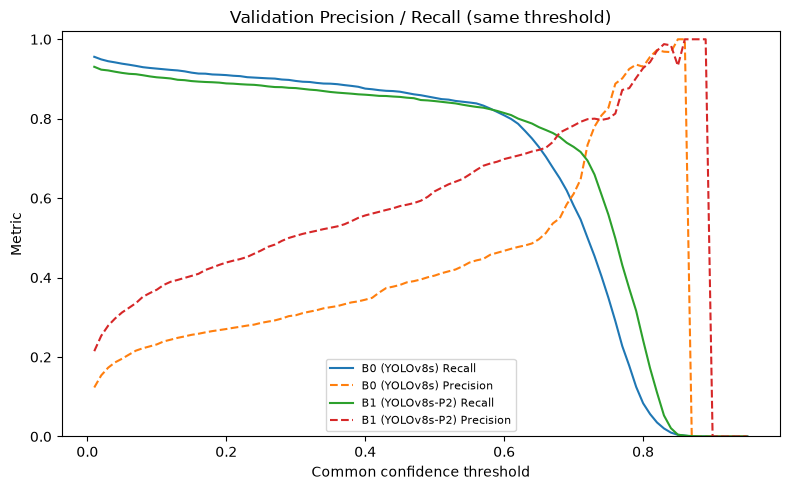

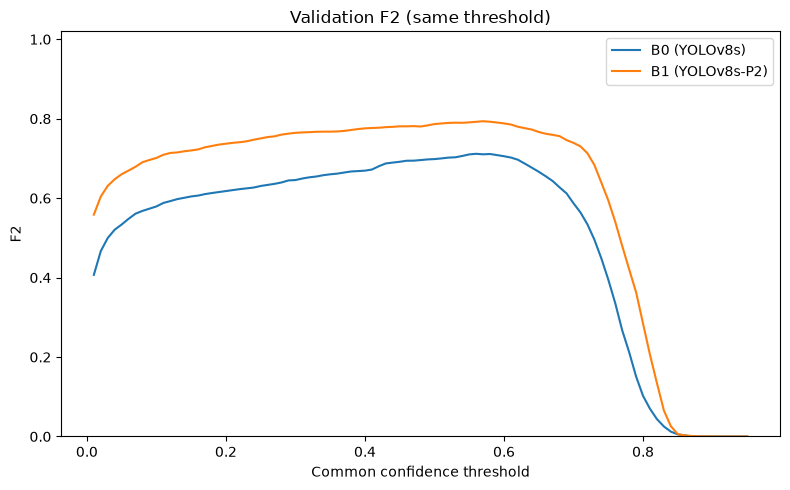

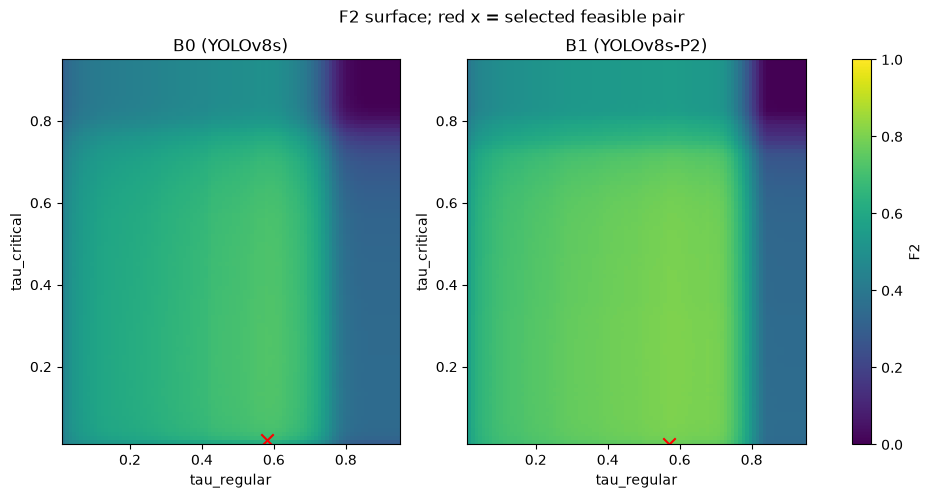

,model,tau_critical,tau_regular,F2,critical_recall,R_Open_circuit,R_Short,Board_FR (defect→PASS),Board_FA (clean→DEFECTIVE)
0,B0 (YOLOv8s),0.02,0.58,0.680564,0.955882,0.942748,0.969758,0.0,N/A
1,B1 (YOLOv8s-P2),0.01,0.57,0.779297,0.955882,0.942748,0.969758,0.0,N/A


Threshold configuration written: /Users/duytan/orca/projects/PCB-DetectionImprove/configs/threshold_yolov8s.yaml
Sweep CSV: /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_B1_yolov8s_threshold/dual_threshold_sweep.csv
Artifacts directory: /Users/duytan/orca/projects/PCB-DetectionImprove/evaluation/B0_B1_yolov8s_threshold


In [4]:
OUT=ROOT/'evaluation/B0_B1_yolov8s_threshold'; OUT.mkdir(parents=True,exist_ok=True)
sweep_path=OUT/'dual_threshold_sweep.csv'; sweep_df.to_csv(sweep_path,index=False)

# Đường cong một ngưỡng chung là đối chứng dễ đọc; quyết định khóa vẫn lấy từ dual-threshold feasible grid.
common=[]
for name,df in sweep_tables.items():
 diag=df[df.tau_critical==df.tau_regular].sort_values('tau_critical').copy()
 common.append(diag)
fig,ax=plt.subplots(figsize=(8,5))
for d in common:
 name=d.model.iloc[0];ax.plot(d.tau_critical,d.recall,label=f'{name} Recall');ax.plot(d.tau_critical,d.precision,linestyle='--',label=f'{name} Precision')
ax.set(xlabel='Common confidence threshold',ylabel='Metric',ylim=(0,1.02),title='Validation Precision / Recall (same threshold)');ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'precision_recall_vs_conf.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(8,5))
for d in common:ax.plot(d.tau_critical,d.F2,label=d.model.iloc[0])
ax.set(xlabel='Common confidence threshold',ylabel='F2',ylim=(0,1.02),title='Validation F2 (same threshold)');ax.legend();fig.tight_layout();fig.savefig(OUT/'f2_vs_conf.png',dpi=180);plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(name,df) in zip(axes,sweep_tables.items()):
 grid=df.pivot(index='tau_critical',columns='tau_regular',values='F2').sort_index(ascending=True)
 im=ax.imshow(grid.values,origin='lower',aspect='auto',extent=[TAUS.min(),TAUS.max(),TAUS.min(),TAUS.max()],vmin=0,vmax=1,cmap='viridis')
 feasible=df[df.feasible]
 if not feasible.empty:
  pick=feasible.sort_values(['F2','precision','tau_regular','tau_critical'],ascending=[False,False,False,False]).iloc[0]
  ax.scatter(pick.tau_regular,pick.tau_critical,marker='x',s=80,c='red')
 ax.set(title=name,xlabel='tau_regular',ylabel='tau_critical')
fig.colorbar(im,ax=axes.ravel().tolist(),label='F2');fig.suptitle('F2 surface; red x = selected feasible pair');fig.savefig(OUT/'dual_threshold_f2_surface.png',dpi=180,bbox_inches='tight');plt.show()

if len(selected_rows)==len(CHECKPOINTS):
 selected_by_model={row['model']:row for row in selected_rows}
 config={'version':1,'experiment_family':'YOLOv8s','selected_on':'validation','test_not_used_for_threshold':True,
  'locked_at_utc':datetime.now(timezone.utc).isoformat(),
  'selection_rule':{'name':'constrained_dual_threshold_max_f2','beta':BETA,'critical_classes':['Open_circuit','Short'],
   'constraints':{'critical_recall_min':CRITICAL_RECALL_MIN,'per_critical_class_recall_min':PER_CRITICAL_RECALL_MIN,'board_fr_max':BOARD_FR_MAX},
   'objective':'max_micro_F2_within_feasible_region','sweep_start':float(TAUS[0]),'sweep_end':float(TAUS[-1]),'sweep_step':0.01,
   'matching_iou':MATCH_IOU,'class_aware':True,'one_to_one':True,'nms_iou':NMS_IOU,
   'tie_break':['precision_desc','tau_regular_desc','tau_critical_desc']},
  'board_level_rule':'DEFECTIVE if any accepted detection remains after its class-group threshold; otherwise PASS',
  'board_metrics':{'unit':'image','defective_images':int(sum(len(g)>0 for g in model_records[next(iter(model_records))][0])),
   'clean_images':0,'board_fa':'N/A; validation has no clean images','board_fr_definition':'defective image predicted PASS'},
  'validation_split':str(VAL_TXT.relative_to(ROOT)),
  'validation_split_sha256':hashlib.sha256(VAL_TXT.read_bytes()).hexdigest(),
  'sweep_csv':str(sweep_path.relative_to(ROOT)),'sweep_csv_sha256':hashlib.sha256(sweep_path.read_bytes()).hexdigest(),
  'models':{}}
 for model_name,checkpoint in CHECKPOINTS.items():
  row=selected_by_model[model_name]
  config['models']['B0' if model_name.startswith('B0') else 'B1']={'model':model_name,'checkpoint':str(checkpoint.relative_to(ROOT)),
   'checkpoint_sha256':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),'tau_critical':float(row['tau_critical']),
   'tau_regular':float(row['tau_regular']),'validation_F2':float(row['F2']),'validation_precision':float(row['precision']),
   'validation_recall':float(row['recall']),'validation_critical_recall':float(row['critical_recall']),
   'validation_recall_open_circuit':float(row['recall_open_circuit']),'validation_recall_short':float(row['recall_short']),
   'validation_board_fr':float(row['board_fr_defect_predicted_pass']),'validation_board_fa':'N/A'}
 config_path=ROOT/'configs/threshold_yolov8s.yaml';config_path.write_text(yaml.safe_dump(config,sort_keys=False,allow_unicode=True),encoding='utf-8')
 display(pd.DataFrame([{'model':n,'tau_critical':r['tau_critical'],'tau_regular':r['tau_regular'],'F2':r['F2'],
  'critical_recall':r['critical_recall'],'R_Open_circuit':r['recall_open_circuit'],'R_Short':r['recall_short'],
  'Board_FR (defect→PASS)':r['board_fr_defect_predicted_pass'],'Board_FA (clean→DEFECTIVE)':'N/A'} for n,r in selected_by_model.items()]))
 print('Threshold configuration written:',config_path)
else:
 print('Threshold YAML NOT written: at least one model has no feasible pair. Review constraints as a documented decision before any rerun.')
print('Sweep CSV:',sweep_path)
print('Artifacts directory:',OUT)

## 5. Kiểm tra trước khi khóa
- Chỉ nhận ngưỡng nếu cả B0 và B1 có cặp feasible; đọc bảng đã chọn và kiểm tra checksum trong YAML.
- `Board_FA` không đo được trên validation này vì không có ảnh sạch. Không diễn giải N/A thành 0.
- Đây là cấu hình riêng YOLOv8s, không thay đổi threshold YOLO11 trong `configs/threshold.yaml`.
- Sau khi người nghiên cứu rà soát tiêu chí và kết quả, mới commit khóa threshold. Không chạy lại test để chọn/nghiệm thu threshold.